# Bagian 3. Operasi Morfologi pada Citra Biner

In [17]:
# === SEL 1: PERSIAPAN P6 (KODE 1.1 & TEPI_CANNY DARI KODE 1.3) ===
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/simuteh-2330511077/notebook

import sys, json
sys.path.append("../src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md  = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb  = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

print("Setup P6 berhasil! Jumlah data:", len(label))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511077/notebook
Setup P6 berhasil! Jumlah data: 60


### Langkah 3.1 Lembar hitung manual.

### Lembar Hitung Manual Operasi Morfologi Citra Biner

Diketahui citra biner $B$ berukuran $9 \times 9$ (indeks baris $r = 0\dots8$, kolom $c = 0\dots8$), *structuring element* (SE) persegi $3 \times 3$ penuh bernilai $1$, dan piksel di luar batas citra bernilai $0$:

$$
B = \begin{bmatrix}
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 0 & 0 & 1 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 1 & 1 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}
$$

---

#### **a) Jumlah Komponen Terhubung (Konektivitas 4 dan Konektivitas 8)**

* **Konektivitas 4 = `4` komponen:**
  1. **Komponen 1 (Bercak $3\times3$ berlubang):** 8 piksel pada baris `1..3`, kolom `1..3` (kecuali pusat `(2, 2)`) yang terhubung secara horizontal dan vertikal.
  2. **Komponen 2 (Titik derau):** 1 piksel tunggal pada `(2, 7)`.
  3. **Komponen 3 (Piksel diagonal):** 1 piksel tunggal pada `(4, 4)` (terpisah dari piksel `(3, 3)` karena tetangga diagonal tidak dihitung pada konektivitas 4).
  4. **Komponen 4 (Garis tipis):** 6 piksel berderet horizontal pada baris `7`, kolom `1..6`.

* **Konektivitas 8 = `3` komponen:**
  1. **Komponen 1 (Bercak $3\times3$ + piksel diagonal):** 9 piksel gabungan dari bercak `(1..3, 1..3)` dan piksel `(4, 4)` yang terhubung secara diagonal melalui `(3, 3)`–`(4, 4)`.
  2. **Komponen 2 (Titik derau):** 1 piksel tunggal pada `(2, 7)`.
  3. **Komponen 3 (Garis tipis):** 6 piksel berderet horizontal pada baris `7`, kolom `1..6`.

---

#### **b) Hasil Erosi ($B \ominus SE$) dan Hasil Opening ($B \circ SE$)**

* **Langkah Erosi ($B \ominus SE$):** Piksel keluaran bernilai `1` hanya jika **seluruh 9 piksel** di dalam jendela SE $3\times3$ bernilai `1`. Pada citra $B$, bercak $3\times3$ memiliki lubang `0` di `(2, 2)`, titik `(2, 7)` dan `(4, 4)` berdiri sendiri, sedangkan garis di baris `7` hanya setebal 1 piksel. Karena tidak ada jendela $3\times3$ yang terisi penuh, seluruh piksel tererosi menjadi `0`.
* **Langkah Opening ($B \circ SE = (B \ominus SE) \oplus SE$):** Dilasi terhadap matriks nol tetap menghasilkan matriks nol seluruhnya.

$$
B \ominus SE = B \circ SE = \begin{bmatrix}
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}
$$

---

#### **c) Hasil Closing ($B \bullet SE = (B \oplus SE) \ominus SE$)**

1. **Tahap Dilasi ($B \oplus SE$):** Setiap piksel `1` diperluas ke 8 tetangganya:
   * Bercak `(1..3, 1..3)` melebar menjadi kotak penuh `(0..4, 0..4)` sehingga **lubang di `(2, 2)` tertutup menjadi `1`**.
   * Titik derau `(2, 7)` melebar menjadi kotak $3\times3$ di `(1..3, 6..8)`.
   * Piksel `(4, 4)` melebar ke `(3..5, 3..5)` dan garis `(7, 1..6)` melebar ke `(6..8, 0..7)`, sehingga **celah vertikal di `(5, 4)` dan `(6, 4)` terisi `1`** (menjembatani bercak, piksel diagonal, dan garis).
2. **Tahap Erosi kembali ($(B \oplus SE) \ominus SE$):**
   * Lubang bercak di `(2, 2)` tetap tertutup (kotak $3\times3$ utuh).
   * Titik derau menyusut kembali ke `(2, 7)`.
   * Celah **`(5, 4)`** dan **`(6, 4)`** tetap bernilai `1` karena jendela $3\times3$ di sekitarnya (kolom `3..5`, baris `4..7`) telah terisi penuh saat dilasi, sehingga bercak, piksel diagonal, dan garis tipis menyatu.

$$
B \bullet SE = \begin{bmatrix}
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 1 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 1 & 1 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}
$$

---

#### **d) Hasil Opening terhadap Citra Hasil Closing ($(B \bullet SE) \circ SE$)**

1. **Tahap Erosi pada hasil Closing ($(B \bullet SE) \ominus SE$):** Hanya piksel `(2, 2)` yang dikelilingi 9 piksel `1` secara penuh, sehingga erosi menyisakan satu piksel `1` pada `(2, 2)`, sementara titik derau `(2, 7)`, jembatan `(4..6, 4)`, dan garis baris `7` terhapus menjadi `0`.
2. **Tahap Dilasi kembali ($((B \bullet SE) \ominus SE) \oplus SE$):** Piksel `(2, 2)` melebar kembali menjadi bercak padat $3\times3$ pada `(1..3, 1..3)` tanpa lubang dan bebas dari derau maupun garis tipis.

$$
(B \bullet SE) \circ SE = \begin{bmatrix}
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}
$$

### Langkah 3.2 Citra biner awal.

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.998                   159              10           0.707
1  teh_021.png          0.998                   123               3           0.106
2  teh_011.png          0.996                   210               0               -


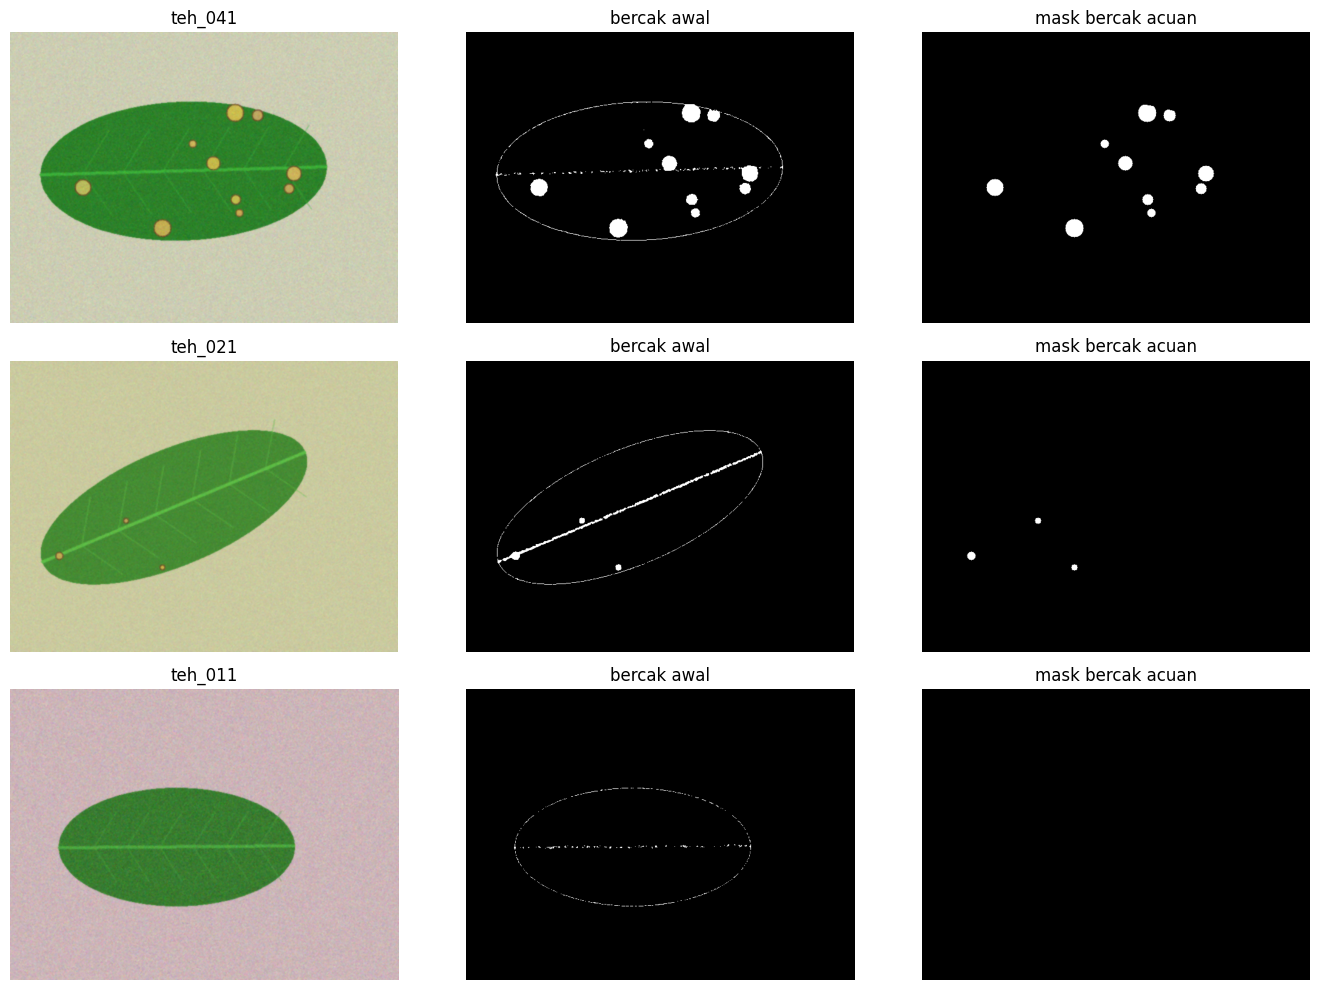

In [18]:
# === SEL 2: LANGKAH 3.2 (KODE 3.1) - MASK DAUN AWAL & BERCAK AWAL ===
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    b0 = bercak_awal(pra, m_daun, kanal=2, k=4.0)
    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])
    panel += [pra, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

### Langkah 3.3 Enam operasi.

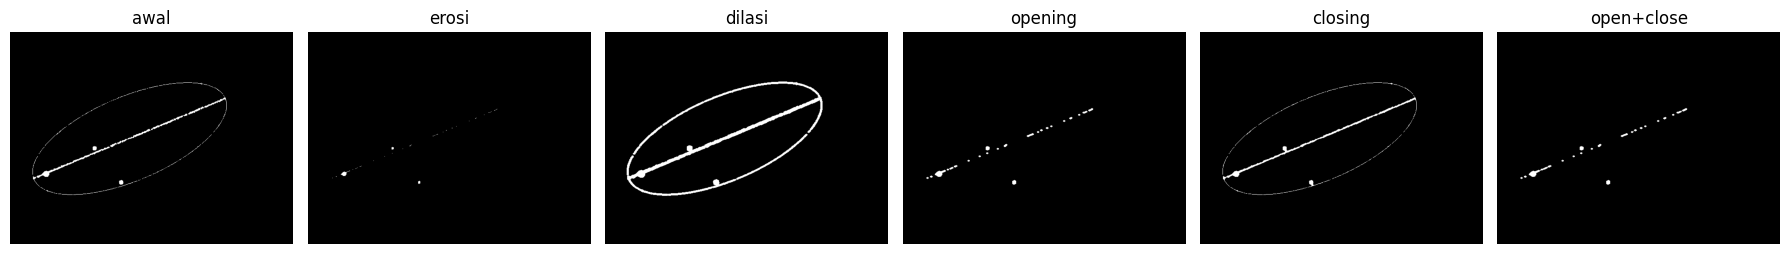

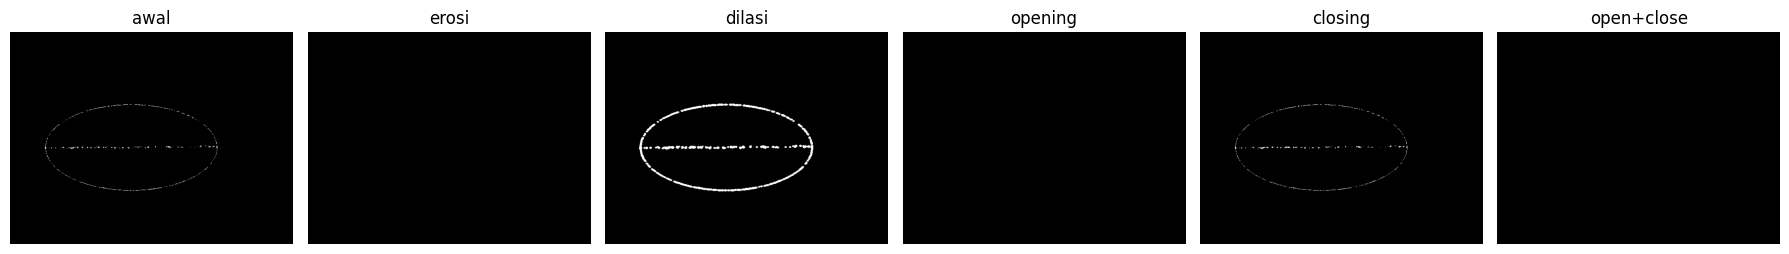

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       123    2822  0.106
1   teh_021.png       erosi        36     195  0.386
2   teh_021.png      dilasi         1    9174  0.034
3   teh_021.png     opening        23     888  0.326
4   teh_021.png     closing        99    3031    0.1
5   teh_021.png  open+close        18     909  0.319
6   teh_011.png        awal       210     786      -
7   teh_011.png       erosi         0       0      -
8   teh_011.png      dilasi        40    5357      -
9   teh_011.png     opening         0       0      -
10  teh_011.png     closing       193     835      -
11  teh_011.png  open+close         0       0      -


In [19]:
# === SEL 3: LANGKAH 3.3 (KODE 3.2) - EROSI, DILASI, OPENING, DAN CLOSING ===
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
    }

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    b0 = bercak_awal(pra, mask_daun_awal(pra))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([
            nama, nm, jumlah_komponen(m), int((m > 0).sum()),
            round(iou(m, mb), 3) if mb.any() else "-"
        ])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()

print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Langkah 3.4 Eksperimen ambang dan SE.

In [20]:
# === SEL 4: LANGKAH 3.4 (KODE 3.3) - EKSPERIMEN K, BENTUK, DAN UKURAN SE ===
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([
                    d.kelas, k, nb, uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan
                ])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.74   0.23        19.70  82.95  14.15
          5       0.78   0.34         3.30   4.85   5.25
          7       0.79   0.56         0.65   1.15   0.40
  persegi 3       0.76   0.24         8.80  31.35   8.80
          5       0.79   0.47         1.00   3.10   1.65
          7       0.77   0.62         0.90   0.40   0.00
  silang  3       0.74   0.23        19.70  82.95  14.15
          5       0.79   0.32         6.95  13.30   9.05
          7       0.81   0.54         0.60   3.45   1.00
4 elips   3       0.80   0.37        14.60  78.20  13.90
          5       0.81   0.51         0.55   3.70   1.45
          7       0.79   0.63         0.60   0.40   0.00
  persegi 3       0.81   0.40         5.20  28.00   6.75
          5       0.79   0.60         0.75   1.10   0.30
          7       0.75   0.61  

#### Tabel 9. Ringkasan Eksperimen Structuring Element (SE) untuk $k = 4$

| Bentuk SE | Ukuran | IoU berat | IoU ringan | Galat jumlah berat | Galat jumlah ringan | Galat jumlah sehat |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **persegi** | 3 | 0.807 | 0.404 | 5.20 | 28.00 | 6.75 |
| **persegi** | 5 | 0.794 | 0.600 | 0.75 | 1.10 | 0.30 |
| **persegi** | 7 | 0.755 | 0.610 | 0.95 | 0.40 | 0.00 |
| **elips** | 3 | 0.797 | 0.370 | 14.60 | 78.20 | 13.90 |
| **elips** | 5 | **0.812** | **0.510** | **0.55** | **3.70** | **1.45** |
| **elips** | 7 | 0.787 | 0.627 | 0.60 | 0.40 | 0.00 |
| **silang** | 3 | 0.797 | 0.370 | 14.60 | 78.20 | 13.90 |
| **silang** | 5 | 0.818 | 0.504 | 1.60 | 10.85 | 2.55 |
| **silang** | 7 | 0.800 | 0.612 | 0.50 | 0.55 | 0.05 |

### Langkah 3.5 Gradien morfologi sebagai tepi daun.

In [21]:
# === SEL 5: LANGKAH 3.5 (KODE 3.4)===
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))  # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])

print("=== Perbandingan F1 Gradien Morfologi vs Canny (Batas Daun) ===")
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3))

=== Perbandingan F1 Gradien Morfologi vs Canny (Batas Daun) ===
                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.823     0.695
gelap                          0.945     0.873
kontras_rendah                 0.253     0.000
normal                         0.999     0.930
terang                         0.971     0.932


### Langkah 3.6 Kerjakan sendiri: tampilkan elemen SE persegi, elips, dan silang berukuran
3, 5, dan 7 dengan cv2.getStructuringElement dalam satu panel. Gunakan panel ini
untuk menjelaskan hasil eksperimen pada Kode 3.3.

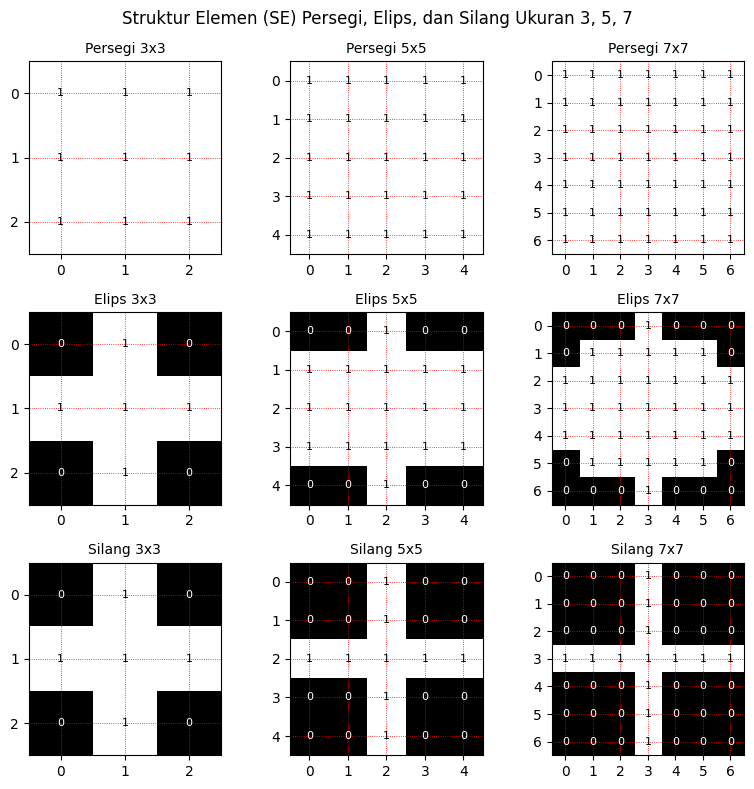

In [22]:

# Langkah 3.6 (Kerjakan sendiri): Panel 3x3 elemen SE persegi, elips, silang ukuran 3, 5, 7
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
daftar_se = [("Persegi (MORPH_RECT)", cv2.MORPH_RECT),
             ("Elips (MORPH_ELLIPSE)", cv2.MORPH_ELLIPSE),
             ("Silang (MORPH_CROSS)", cv2.MORPH_CROSS)]

for i, (nama_se, kode_se) in enumerate(daftar_se):
    for j, uk in enumerate([3, 5, 7]):
        mat_se = cv2.getStructuringElement(kode_se, (uk, uk))
        axes[i, j].imshow(mat_se, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(f"{nama_se.split()[0]} {uk}x{uk}", fontsize=10)
        axes[i, j].set_xticks(range(uk))
        axes[i, j].set_yticks(range(uk))
        axes[i, j].grid(color="red", linestyle=":", linewidth=0.6)
        # Tampilkan angka 0/1 di dalam kotak SE
        for y in range(uk):
            for x in range(uk):
                axes[i, j].text(x, y, int(mat_se[y, x]), ha="center", va="center",
                                color="black" if mat_se[y, x] == 1 else "white", fontsize=8)

plt.suptitle("Struktur Elemen (SE) Persegi, Elips, dan Silang Ukuran 3, 5, 7", fontsize=12)
plt.tight_layout()
plt.show()

### Jawaban Pertanyaan Analisis Bagian 3

**P3.1 — Penghapusan Bercak Berlubang pada Erosi/Opening serta Dampak Celah pada Closing**
* **Mengapa erosi saja dan opening saja menghapus bercak berlubang:** Pada operasi erosi biner dengan SE persegi $3\times3$, piksel pusat hanya dipertahankan bernilai `1` apabila seluruh 9 piksel di dalam jendela $3\times3$ bernilai `1`[cite: 15]. Karena bercak $3\times3$ pada matriks $B$ memiliki lubang bernilai `0` di pusat `(2, 2)`, tidak ada satu pun posisi jendela yang terisi penuh sehingga seluruh piksel bercak tererosi menjadi `0` (dan *opening* yang diawali erosi ikut menghasilkan matriks nol)[cite: 15, 18].
* **Apa yang terjadi pada celah saat closing dan risikonya bagi SIMUTEH:** Pada *closing* (dilasi lalu erosi), tahap dilasi memperluas piksel `(4, 4)` dan garis baris `7` sehingga keduanya saling bersentuhan dan mengisi celah vertikal `(5, 4)` serta `(6, 4)` menjadi `1`[cite: 15, 18]. Saat dierosi kembali, jembatan di `(5, 4)` dan `(6, 4)` tetap bertahan sehingga menyatukan bercak, piksel diagonal, dan garis tulang daun menjadi satu komponen besar[cite: 15, 18]. Di SIMUTEH, melakukan *closing* sebelum *opening* berisiko menyatukan titik derau atau potongan tulang daun dengan bercak asli, sehingga luas bercak membengkak dan jumlah bercak menjadi salah hitung.

#### **P3.2 — Pemilihan Konektivitas (4 vs 8) untuk Menghitung Bercak**
* **Konektivitas yang lebih tepat:** **Konektivitas 8** lebih tepat digunakan untuk menghitung komponen bercak[cite: 18].
* **Contoh dari lembar hitung dan alasan bentuk nyata:** Pada matriks $B$ Langkah 3.1, bercak $3\times3$ di `(1..3, 1..3)` dan piksel `(4, 4)` terhitung sebagai **2 komponen terpisah** pada konektivitas 4 (total `4` komponen), tetapi menyatu menjadi **1 komponen** pada konektivitas 8 (total `3` komponen)[cite: 15, 18]. Pada citra daun nyata, bercak penyakit berbentuk membulat atau tidak beraturan sehingga tepi pikselnya sering bersentuhan secara diagonal akibat diskretisasi kisi piksel; konektivitas 4 akan memecah satu bercak yang menyempit diagonal menjadi beberapa bercak terpisah, sedangkan konektivitas 8 menjaganya tetap utuh sebagai satu objek[cite: 18].

#### **P3.3 — Perilaku Opening vs Closing pada Kode 3.2 serta Sisa Tulang Daun**
* **Mengapa opening membuang titik derau & tepi daun, sedangkan closing tidak:** Titik derau dan tepi daun tipis memiliki ketebalan hanya 1–2 piksel (lebih kecil daripada diameter SE elips $5\times5$), sehingga tahap erosi pada *opening* langsung melenyapkannya sebelum dilasi mengembalikan ukuran bercak utama[cite: 16, 18]. Sebaliknya, *closing* diawali oleh **dilasi** yang justru memperbesar setiap titik derau dan menyambung potongan tepi daun yang berdekatan sehingga jumlah komponen hampir tidak berkurang[cite: 16, 18].
* **Mengapa potongan tulang daun pada daun sehat masih tersisa setelah opening:** Pada daun sehat (`teh_011.png`), bagian pangkal tulang daun utama (*midrib*) memiliki lebar penampang yang cukup tebal ($\ge 5$ piksel) dan kontras kecerahan yang lolos ambang `median + k * MAD`, sehingga tidak habis tererosi oleh SE elips $5\times5$ dan masih menyisakan potongan memanjang setelah *opening* (yang selanjutnya akan disaring menggunakan fitur bentuk pada Bagian 4)[cite: 16, 18, 19].

#### **P3.4 — Pemilihan Kombinasi `k`, Bentuk, dan Ukuran SE (Tabel 9)**
* **Kombinasi yang dipilih:** **`k = 4`, bentuk `elips`, dan ukuran `5 x 5`**[cite: 17, 18].
* **Trade-off antara bercak kelas ringan dan bercak palsu daun sehat:**
  * Pada **`k = 3`**, ambang terlalu rendah sehingga banyak derau lolos (galat jumlah `ringan` mencapai `82.95` pada ukuran 3 dan `4.85` pada elips 5, serta daun `sehat` memiliki `5.25` bercak palsu). Sebaliknya, pada **`k = 6`**, daun sehat bersih (`0.00`), tetapi ambang terlalu tinggi sehingga bercak pudar pada kelas `berat` ikut terpotong (`IoU berat` turun dari `0.812` menjadi `0.76`).
  * Pada **`k = 4` dan SE `elips 5x5`**, diperoleh keseimbangan terbaik antara ketepatan bentuk wilayah bercak (`IoU berat = 0.812`, `IoU ringan = 0.510`) dan galat jumlah bercak berat yang sangat kecil (`0.55`)[cite: 17, 18]. Ukuran `3x3` masih meloloskan terlalu banyak derau (`galat ringan = 78.20`, `sehat = 13.90`), sedangkan ukuran `7x7` berisiko mengikis bercak kecil pada kelas ringan[cite: 17, 18]. Sisa galat kecil pada daun sehat (`1.45` komponen berupa potongan tulang daun) pada kombinasi `elips 5x5` akan dibersihkan secara tuntas oleh penyaringan luas, kebulatan, dan rasio aspek pada Bagian 4[cite: 18, 19]. Bentuk `elips` dipilih karena paling sesuai dengan geometri bercak daun yang membulat[cite: 17, 18].
* **Mengapa hasil SE `elips 3x3` identik dengan SE `silang 3x3`:** Pada ukuran $3\times3$, fungsi `cv2.getStructuringElement` menghasilkan matriks biner yang sama persis untuk `MORPH_ELLIPSE` dan `MORPH_CROSS`, yaitu bentuk tanda tambah `[[0, 1, 0], [1, 1, 1], [0, 1, 0]]`, sehingga seluruh nilai IoU (`0.797` dan `0.370`) dan galat jumlahnya (`14.60`, `78.20`, `13.90`) identik[cite: 17, 18].

#### **P3.5 — Keunggulan Gradien Morfologi vs Canny untuk Batas Daun**
* **Mengapa gradien morfologi lebih baik untuk batas daun (terutama kontras rendah):** Gradien morfologi ($\text{dilasi} - \text{erosi}$) dihitung langsung dari **`mask_daun_awal` (hasil Otsu pada kanal Saturasi S)** yang telah memisahkan daun hijau pekat dari latar nampan pucat secara utuh sebagai wilayah biner[cite: 7, 18, 19]. Karena bekerja pada mask biner yang sudah terpisah, batas daun tetap utuh meskipun citra berada pada kondisi `kontras_rendah` atau `bayangan`, tanpa terganggu oleh tekstur tulang daun di bagian dalam[cite: 18, 19]. Sebaliknya, Canny bekerja pada gradien intensitas yang melemah saat kontras rendah[cite: 18, 19].
* **Kapan Canny tetap diperlukan:** Canny tetap diperlukan apabila sistem membutuhkan deteksi tepi langsung dari citra skala keabuan/kanal warna tanpa melewati tahap segmentasi biner terlebih dahulu (misalnya pada tahap ekstraksi fitur kontur halus di P9)[cite: 13, 19].

# Bagian 4. Komponen Terhubung dan Pengukuran Bercak

### Langkah 4.1 — Lembar Hitung Manual Pengukuran Komponen

Diketahui skala konversi dari lembar hitung P2: $1\text{ piksel} = 0{,}4375\text{ mm}$, sehingga luas $1\text{ piksel} = (0{,}4375)^2 = 0{,}19140625\text{ mm}^2$[cite: 5, 19]. Keliling dihitung sebagai jumlah sisi piksel objek yang berbatasan langsung dengan latar (`0`)[cite: 19].

---

#### **a) Bercak $3 \times 3$ (Hasil Soal 3.1 Butir d)**
* **Luas (piksel):**
  $$\text{Luas}_{\text{px}} = 3 \times 3 = 9\text{ piksel}$$
* **Luas ($\text{mm}^2$):**
  $$\text{Luas}_{\text{mm}^2} = 9 \times (0{,}4375)^2 = 9 \times 0{,}19140625 = 1{,}7227\text{ mm}^2 \approx 1{,}72\text{ mm}^2$$
* **Keliling (sisi piksel berbatasan dengan latar):**
  $$\text{Keliling} = 4 \text{ sisi} \times 3\text{ piksel} = 12\text{ piksel}$$
* **Kebulatan:**
  $$\text{Kebulatan} = \frac{4 \pi \times \text{Luas}_{\text{px}}}{\text{Keliling}^2} = \frac{4 \pi \times 9}{12^2} = \frac{36 \pi}{144} = \frac{\pi}{4} \approx 0{,}7854 \approx 0{,}79$$
* **Rasio Aspek:**
  $$\text{Rasio Aspek} = \frac{\text{sisi terpanjang}}{\text{sisi terpendek}} = \frac{3}{3} = 1{,}00$$

---

#### **b) Garis Tipis $1 \times 6$ Piksel (Baris ke-8 Citra B)**
* **Luas (piksel):**
  $$\text{Luas}_{\text{px}} = 1 \times 6 = 6\text{ piksel}$$
* **Luas ($\text{mm}^2$):**
  $$\text{Luas}_{\text{mm}^2} = 6 \times (0{,}4375)^2 = 6 \times 0{,}19140625 = 1{,}1484\text{ mm}^2 \approx 1{,}15\text{ mm}^2$$
* **Keliling (sisi piksel berbatasan dengan latar):**
  $$\text{Keliling} = 6\text{ (atas)} + 6\text{ (bawah)} + 1\text{ (kiri)} + 1\text{ (kanan)} = 14\text{ piksel}$$
* **Kebulatan:**
  $$\text{Kebulatan} = \frac{4 \pi \times \text{Luas}_{\text{px}}}{\text{Keliling}^2} = \frac{4 \pi \times 6}{14^2} = \frac{24 \pi}{196} \approx 0{,}3847 \approx 0{,}38$$
* **Rasio Aspek:**
  $$\text{Rasio Aspek} = \frac{\text{sisi terpanjang}}{\text{sisi terpendek}} = \frac{6}{1} = 6{,}00$$

---

#### **c) Aturan Sederhana Membedakan Bercak dari Potongan Tulang Daun**
* Bercak sejati berbentuk kompak/membulat sehingga memiliki **kebulatan tinggi** ($0{,}79$) dan **rasio aspek mendekati 1** ($1{,}00$)[cite: 19]. Sebaliknya, potongan tulang daun berbentuk memanjang sehingga memiliki **kebulatan rendah** ($0{,}38$) dan **rasio aspek jauh lebih besar** ($6{,}00$)[cite: 19].
* **Aturan penyaringan:** Sebuah komponen dipertahankan sebagai bercak apabila memenuhi $\text{Kebulatan} \ge 0{,}50$ **dan** $\text{Rasio Aspek} \le 1{,}80$ (serta $\text{Luas} \ge 20\text{ piksel}$ pada citra kerja $640 \times 480$).

### Langkah 4.2 Label dan ukur.

konektivitas 4: 10 komponen
konektivitas 8: 10 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      748    143.17        101.0       0.92         1.03  370  133
1      2      327     62.59         68.5       0.88         1.10  407  137
2      3      176     33.69         48.6       0.94         1.05  301  183
3      4      496     94.94         81.4       0.94         1.00  334  216
4      5      592    113.31         92.8       0.86         1.00  467  232
5      6      639    122.31         92.4       0.94         1.04  120  256
6      7      270     51.68         61.1       0.91         1.05  460  257
7      8      264     50.53         59.5       0.94         1.06  371  275
8      9      170     32.54         46.4       0.99         1.08  377  297
9     10      736    140.88         99.3       0.94         1.03  251  323

Total luas bercak terdeteksi (px): 4418 | Total luas acuan mb (px): 4093


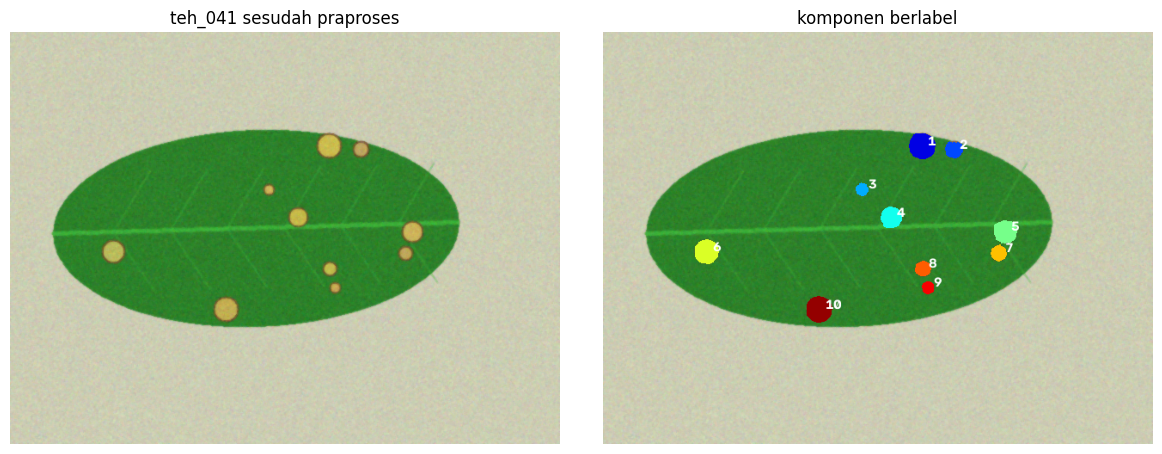

In [23]:
# === SEL 6: LANGKAH 4.2 (KODE 4.1) - KOMPONEN TERHUBUNG & PENGUKURAN BERCAK ===
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z=200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / (keliling ** 2)
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([
            i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
            round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])
        ])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
m_daun = mask_daun_awal(pra)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
print(f"\nTotal luas bercak terdeteksi (px): {tabel_kom['luas_px'].sum()} | Total luas acuan mb (px): {(mb > 0).sum()}")

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

#### Tabel 10. Ukuran Setiap Bercak pada `teh_041.png`

| Label | Luas (px) | Luas ($\text{mm}^2$) | Keliling (px) | Kebulatan | Rasio aspek | Pusat $(x, y)$ |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 1 | 748 | 143.17 | 101.0 | 0.92 | 1.03 | (370, 133) |
| 2 | 327 | 62.59 | 68.5 | 0.88 | 1.10 | (407, 137) |
| 3 | 176 | 33.69 | 48.6 | 0.94 | 1.05 | (301, 183) |
| 4 | 496 | 94.94 | 81.4 | 0.94 | 1.00 | (334, 216) |
| 5 | 592 | 113.31 | 92.8 | 0.86 | 1.00 | (467, 232) |
| 6 | 639 | 122.31 | 92.4 | 0.94 | 1.04 | (120, 256) |
| 7 | 270 | 51.68 | 61.1 | 0.91 | 1.05 | (460, 257) |
| 8 | 264 | 50.53 | 59.5 | 0.94 | 1.06 | (371, 275) |
| 9 | 170 | 32.54 | 46.4 | 0.99 | 1.08 | (377, 297) |
| 10 | 736 | 140.88 | 99.3 | 0.94 | 1.03 | (251, 323) |
| **Total** | **4418** | **845.64** | — | — | — | — |

### Langkah 4.3 Saring bercak palsu.

In [24]:
# === SEL 7: LANGKAH 4.3 (KODE 4.2) - PENYARINGAN BERCAK PALSU (TABEL 11) ===
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("\nDaun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.70    1.45   0.65
luas + kebulatan + rasio   0.90    0.70   0.35
luas >= 20                 0.55    2.15   0.85
tanpa saring               0.55    3.70   1.45

Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            5
luas + kebulatan + rasio    4
luas >= 20                  5
tanpa saring                6
Name: palsu, dtype: int64


#### Tabel 11. Hasil Aturan Penyaringan Komponen Bercak pada 60 Citra

| Aturan | Galat jumlah berat | Galat jumlah ringan | Galat jumlah sehat | Daun sehat dengan bercak palsu |
| :--- | :---: | :---: | :---: | :---: |
| **tanpa saring** | 0.55 | 3.70 | 1.45 | 6 |
| **luas >= 20** | 0.55 | 2.15 | 0.85 | 5 |
| **luas + kebulatan** | 0.70 | 1.45 | 0.65 | 5 |
| **luas + kebulatan + rasio** | **0.90** | **0.70** | **0.35** | **4** |

### Langkah 4.4 Kerjakan sendiri: dasar ambang penyaringan.

Ringkasan statistik komponen Benar vs Palsu:
       luas_px                                                     kebulatan        ...             rasio_aspek                                          
         count    mean     std   min    25%    50%     75%     max     count  mean  ...   75%   max       count  mean   std  min   25%   50%   75%    max
status                                                                              ...                                                                  
Benar    197.0  369.84  266.70  17.0  164.0  307.0  540.00  1449.0     197.0  0.89  ...  0.96  1.15       197.0  1.14  0.32  1.0  1.00  1.04  1.10   3.47
Palsu    114.0   50.62   79.65   1.0   17.0   22.0   47.75   529.0     114.0  0.87  ...  1.15  1.18       114.0  2.51  2.94  0.0  1.25  1.25  2.66  19.42

[2 rows x 24 columns]


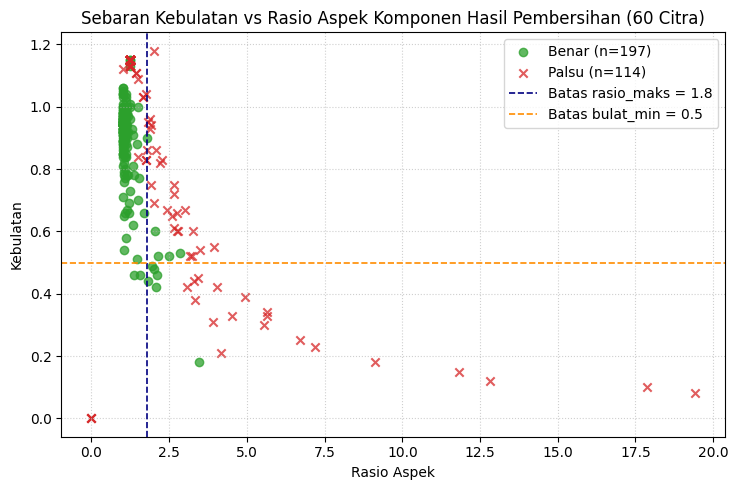

In [25]:
# === SEL 8: LANGKAH 4.4 (KERJAKAN SENDIRI) - DIAGRAM SEBAR KOMPONEN BENAR VS PALSU ===
komp_semua = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    bersih = cv2.morphologyEx(
        cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)),
        cv2.MORPH_CLOSE, SE(5)
    )
    tk, lbl = ukur_komponen(bersih)
    mb_bool = mb > 0
    for _, row in tk.iterrows():
        l_id = int(row["label"])
        mask_k = (lbl == l_id)
        irisan = np.logical_and(mask_k, mb_bool).sum()
        status = "Benar" if irisan > 0.5 * row["luas_px"] else "Palsu"
        komp_semua.append([
            d.nama_file, d.kelas, row["luas_px"], row["kebulatan"], row["rasio_aspek"], status
        ])

df_komp = pd.DataFrame(komp_semua, columns=["nama", "kelas", "luas_px", "kebulatan", "rasio_aspek", "status"])
print("Ringkasan statistik komponen Benar vs Palsu:")
print(df_komp.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].describe().round(2))

plt.figure(figsize=(7.5, 5))
for st, warna, marker in [("Benar", "tab:green", "o"), ("Palsu", "tab:red", "x")]:
    sub = df_komp[df_komp["status"] == st]
    plt.scatter(sub["rasio_aspek"], sub["kebulatan"], c=warna, marker=marker, alpha=0.75, label=f"{st} (n={len(sub)})")

plt.axvline(1.8, color="navy", linestyle="--", linewidth=1.2, label="Batas rasio_maks = 1.8")
plt.axhline(0.5, color="darkorange", linestyle="--", linewidth=1.2, label="Batas bulat_min = 0.5")
plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title("Sebaran Kebulatan vs Rasio Aspek Komponen Hasil Pembersihan (60 Citra)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### Jawaban Pertanyaan Anlaisis Bagian 4

**P4.1 — Perbandingan Kebulatan Bercak vs Garis dan Anomali Kebulatan pada Komponen Kecil**
* **Perbandingan kebulatan:** Pada Langkah 4.1, bercak $3\times3$ memiliki kebulatan **`0,79`** ($\pi/4 \approx 0{,}7854$), sedangkan garis tipis $1\times6$ memiliki kebulatan jauh lebih rendah yaitu **`0,38`** ($0{,}3847$)[cite: 19].
* **Mengapa kebulatan bercak $3\times3$ tidak sama dengan 1:** Nilai kebulatan maksimum $1{,}0$ hanya dicapai oleh lingkaran kontinu yang sempurna ($\text{Luas} = \pi r^2$ dan $\text{Keliling} = 2\pi r$)[cite: 19]. Pada kisi piksel diskret, bercak $3\times3$ berbentuk persegi dengan empat sudut siku-siku yang menambah panjang keliling relatif terhadap luasnya, sehingga rasio $4\pi A / P^2$ bernilai $\pi/4 \approx 0{,}79 < 1$[cite: 19, 21].
* **Mengapa kebulatan hasil OpenCV pada komponen sangat kecil bisa $> 1$:** Fungsi `cv2.arcLength` menghitung keliling melalui pusat piksel kontur secara diagonal ($+\sqrt{2}$ per langkah sudut), bukan mengelilingi sisi terluar piksel seperti pada hitungan kotak manual[cite: 19]. Akibatnya, pada komponen yang sangat kecil (misalnya 4–9 piksel), nilai keliling yang dihasilkan `cv2.arcLength` menjadi lebih pendek daripada keliling kotak sebenarnya sehingga pembagi $P^2$ mengecil dan nilai $4\pi A / P^2$ dapat melampaui `1,0`[cite: 19, 21].

#### **P4.2 — Asumsi Konversi Piksel ke Milimeter dan Penanganan Perubahan Jarak Potret**
* **Asumsi yang mendasari konversi $1\text{ piksel} = 0{,}4375\text{ mm}$:** Konversi tersebut diperoleh dari model proyeksi kamera lubang jarum (*pinhole*) pada Evaluasi P2 dengan asumsi bahwa **jarak kamera ke daun tetap $Z = 200\text{ mm}$**, bidang daun sejajar dengan bidang sensor kamera, dan citra telah diseragamkan ke **lebar kerja $640\text{ piksel}$** menggunakan parameter panjang fokus kamera yang sama[cite: 5, 19, 21].
* **Dampak jika dipotret dari jarak $30\text{ cm}$ ($300\text{ mm}$) dan cara SIMUTEH mengatasinya:** Karena jarak pemotretan bertambah $1{,}5\times$ lebih jauh ($300\text{ mm} / 200\text{ mm}$), daun tampak lebih kecil pada citra sehingga jumlah piksel bercak menyusut sebesar $(200/300)^2 = 4/9 \approx 0{,}444\times$. Jika tetap dikalikan faktor skala lama ($0{,}4375\text{ mm/px}$), luas bercak dalam $\text{mm}^2$ akan terbaca **55,6% lebih kecil** dari ukuran aslinya[cite: 21]. Pada foto lapangan nyata, SIMUTEH mengatasinya dengan dua cara: (1) menghitung **persentase luas bercak relatif terhadap luas daun** ($\text{Luas}_{\text{bercak}} / \text{Luas}_{\text{daun}} \times 100\%$) yang bersifat invarian terhadap perubahan jarak kamera[cite: 22], serta (2) meletakkan **penanda kalibrasi fisik** (seperti penggaris/kotak referensi berukuran tetap di tepi nampan) agar rasio $\text{mm/px}$ dapat dihitung ulang secara otomatis pada setiap foto[cite: 21].

#### **P4.3 — Efektivitas Aturan Penyaringan dan Risiko Batas Rasio Aspek**
* **Aturan yang paling efektif membuang bercak palsu:** Berdasarkan **Tabel 11** dan diagram sebar Langkah 4.4, aturan gabungan **`luas + kebulatan + rasio`** ($\text{luas} \ge 20\text{ px}$, $\text{kebulatan} \ge 0{,}5$, dan $\text{rasio aspek} \le 1{,}8$) adalah yang paling efektif membuang bercak palsu[cite: 20, 21]. Aturan ini menurunkan galat jumlah komponen pada daun `ringan` dari `3,70` menjadi **`0,70`**, menurunkan galat pada daun `sehat` dari `1,45` menjadi **`0,35`**, dan menekan jumlah daun sehat yang masih memiliki bercak palsu dari `6` citra menjadi **`4` citra**[cite: 20, 21]. Pada diagram sebar, komponen bercak sejati ("Benar") mengelompok di area kebulatan tinggi ($> 0{,}75$) dan rasio aspek rendah ($1{,}0$–$1{,}4$), sedangkan sisa potongan tulang daun ("Palsu") tersebar di area kebulatan rendah ($< 0{,}5$) dan rasio aspek tinggi ($> 1{,}8$), sehingga kedua garis batas tersebut memisahkan keduanya secara tegas[cite: 21].
* **Risiko aturan rasio aspek pada bercak memanjang atau dua bercak menyatu:** Penggunaan batas $\text{rasio aspek} \le 1{,}8$ menimbulkan *trade-off* yang terlihat pada **Tabel 11**, di mana galat jumlah pada kelas **`berat` meningkat dari `0,55` menjadi `0,90`**[cite: 20, 21]. Ketika dua bercak penyakit yang berdekatan tumbuh melebar hingga saling menyatu (membentuk figur angka delapan) atau ketika bercak nyata berkembang memanjang mengikuti arah urat daun, nilai rasio aspek komponennya melampaui `1,8` sehingga ikut terbuang sebagai objek palsu (*false negative*)[cite: 21].

#### **P4.4 — Perbandingan Luas Total Bercak Hasil Deteksi vs Mask Acuan pada `teh_041.png`**
* **Perbandingan luas dan persentase selisih:** Pada `teh_041.png`, luas total bercak hasil deteksi dan pembersihan morfologi adalah **`4.418 piksel`** ($845{,}64\text{ mm}^2$), sedangkan luas pada mask acuan (`mask_bercak`) adalah **`4.093 piksel`** ($783{,}43\text{ mm}^2$)[cite: 20, 21]. Hasil deteksi **lebih besar** sebesar **`325 piksel`** atau **`+7,94%`** dibandingkan mask acuan (`(4418 - 4093) / 4093 × 100%`)[cite: 21].
* **Tiga penyebab utama pelebaran luas bercak:**
  1. **Cincin kecokelatan di tepi bercak pada kanal R:** Pada batas transisi antara pusat bercak kuning-cokelat dan jaringan daun hijau sehat, terdapat zona peralihan (cincin kecokelatan) yang nilai intensitas kanal R-nya sudah cukup tinggi sehingga ikut melewati ambang `median + 4 × MAD` pada fungsi `bercak_awal`[cite: 7, 21, 30].
  2. **Pengaruh penapis median $3\times3$ saat praproses:** Penapis median meratakan transisi tajam di perbatasan tepi bercak dan daun, sehingga memperlebar zona intensitas menengah di pinggiran bercak[cite: 21, 32].
  3. **Pengaruh operasi morfologi *closing*:** Setelah *opening*, tahap *closing* dengan SE elips $5\times5$ mengisi lekukan kecil di tepi kontur bercak dan sedikit membulatkan batas luarnya, sehingga menambah beberapa piksel di sekeliling keliling bercak[cite: 19, 21].

# Bagian 5. Integrasi: Modul Analisis Bercak SIMUTEH

Tujuan bagian: menggabungkan seluruh temuan Pertemuan 5 dan 6 menjadi modul
bercak.py yang menerima citra hasil praproses dan mengeluarkan jumlah bercak, persen
bercak, dan kelas mutu, lalu mengevaluasinya pada seluruh dataset.

### Langkah 5.1 Kerjakan sendiri: lengkapi modul.

In [26]:
# === SEL 9: LANGKAH 5.1 - MENULIS MODUL LENGKAP src/bercak.py ===
kode_bercak = '''"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,             # kanal terpilih (2 = R)
    "k": 4.0,               # ambang median + k x MAD
    "se_bentuk": "elips",   # "elips", "persegi", "silang"
    "se_open": 5,           # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,          # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,         # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,    # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,     # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

BENTUK = {
    "elips": cv2.MORPH_ELLIPSE,
    "persegi": cv2.MORPH_RECT,
    "silang": cv2.MORPH_CROSS,
}

def se(p, uk):
    return cv2.getStructuringElement(BENTUK[p["se_bentuk"]], (uk, uk))

def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: bila p["se_open"] > 0, lakukan opening dengan SE se(p, p["se_open"])
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, se(p, p["se_open"]))
    # TODO 2: bila p["se_close"] > 0, lakukan closing dengan SE se(p, p["se_close"])
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, se(p, p["se_close"]))
    return biner

def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3: label komponen terhubung (konektivitas 8) dengan cv2.connectedComponentsWithStats
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner, dtype=np.uint8), []

    for i in range(1, n):
        # TODO 4: hitung luas, keliling (cv2.arcLength), kebulatan 4*pi*luas/keliling^2, dan rasio aspek (cv2.minAreaRect)
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not kontur:
            continue
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else float(4.0 * np.pi * A / (keliling ** 2))
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = float(max(w, h) / max(min(w, h), 1.0))

        # TODO 5: simpan ke mask keluar hanya komponen yang memenuhi luas_min, bulat_min, dan rasio_maks
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "label": len(daftar) + 1,
                "luas_px": A,
                "luas_mm2": round(A * (p["mm_per_px"] ** 2), 2),
                "keliling_px": round(keliling, 1),
                "kebulatan": round(kebulatan, 2),
                "rasio_aspek": round(rasio, 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1]),
            })
    return keluar, daftar

def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)

    # TODO 6: hitung persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = 0.0 if luas_daun == 0 else (luas_bercak / luas_daun) * 100.0

    # TODO 7: tentukan kelas dengan batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar,
    }

def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)
'''

with open("../src/bercak.py", "w") as f:
    f.write(kode_bercak)

print("Berhasil menulis ../src/bercak.py!")

Berhasil menulis ../src/bercak.py!


### Langkah 5.2 Evaluasi menyeluruh.

Galat absolut rerata persen bercak: 0.45
Korelasi persen prediksi vs acuan : 0.955
Akurasi kelas                     : 0.9

Matriks Kekeliruan Kelas:
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             19              1      0
Bercak Ringan             0             16      4
Sehat                     0              1     19

Akurasi per Kondisi Cahaya:
kondisi
bayangan          1.00
gelap             1.00
kontras_rendah    0.75
normal            0.83
terang            0.92
Name: benar, dtype: float64


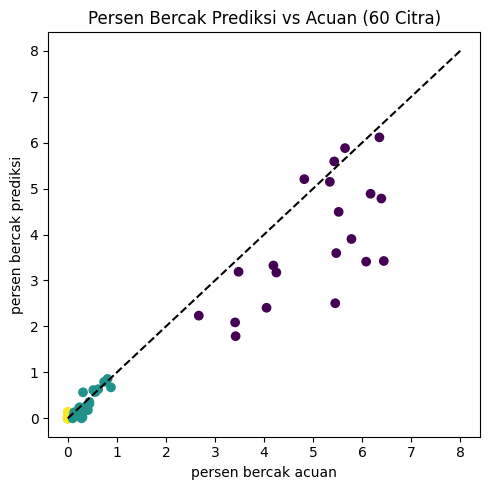

In [27]:
# === SEL 10: LANGKAH 5.2 (KODE 5.2) ===
import importlib, bercak
importlib.reload(bercak)

PB = {}  # memakai parameter optimal temuan P5-P6 (kanal=2, k=4.0, elips 5x5, luas>=20, bulat>=0.5, rasio<=1.8)
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([
        d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
        h["persen_bercak"], jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]
    ])

ev = pd.DataFrame(baris, columns=[
    "nama", "kelas", "kondisi", "persen_acuan",
    "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"
])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print("\nMatriks Kekeliruan Kelas:")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print("\nAkurasi per Kondisi Cahaya:")
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Persen Bercak Prediksi vs Acuan (60 Citra)")
plt.tight_layout()
plt.show()

#### Tabel 12. Ringkasan Evaluasi Modul `bercak.py` pada 60 Citra

| Ukuran | Nilai | Catatan |
| :--- | :---: | :--- |
| **Galat absolut rerata persen bercak** | **0.450%** | Rerata selisih absolut terhadap `persen_bercak` di `label.csv`[cite: 6, 24] |
| **Korelasi persen prediksi dan acuan** | **0.955** | Korelasi linear sangat kuat antara luas prediksi dan acuan[cite: 24] |
| **Akurasi kelas** | **90.0% (0.900)** | 54 dari 60 citra diklasifikasikan tepat (19 Berat, 16 Ringan, 19 Sehat)[cite: 24] |
| **Jumlah daun sehat yang dinilai berbercak** | **1 citra** | `teh_006.png` (kondisi `normal`) diprediksi `Bercak Ringan` (`0,143%`)[cite: 24] |
| **Jumlah daun berbercak yang dinilai sehat** | **4 citra** | Seluruhnya dari kelas `Bercak Ringan` (`teh_029`, `teh_034`, `teh_038`, `teh_039`)[cite: 24] |
| **Kondisi cahaya dengan akurasi terendah** | **`kontras_rendah` (75%)** | 3 dari 12 citra `kontras_rendah` salah kelas (`bayangan` & `gelap` 100%)[cite: 24] |


### Langkah 5.3 (Kerjakan sendiri): Tampilkan setiap citra yang salah kelas


Jumlah citra salah kelas: 6
           nama         kondisi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi    kelas_acuan kelas_prediksi
5   teh_006.png          normal          0.00            0.143             0                4          Sehat  Bercak Ringan
28  teh_029.png  kontras_rendah          0.10            0.000             1                0  Bercak Ringan          Sehat
33  teh_034.png  kontras_rendah          0.28            0.000             1                0  Bercak Ringan          Sehat
37  teh_038.png          terang          0.12            0.069             1                1  Bercak Ringan          Sehat
38  teh_039.png  kontras_rendah          0.30            0.024             2                1  Bercak Ringan          Sehat
45  teh_046.png          normal          3.42            1.788             5                3   Bercak Berat  Bercak Ringan


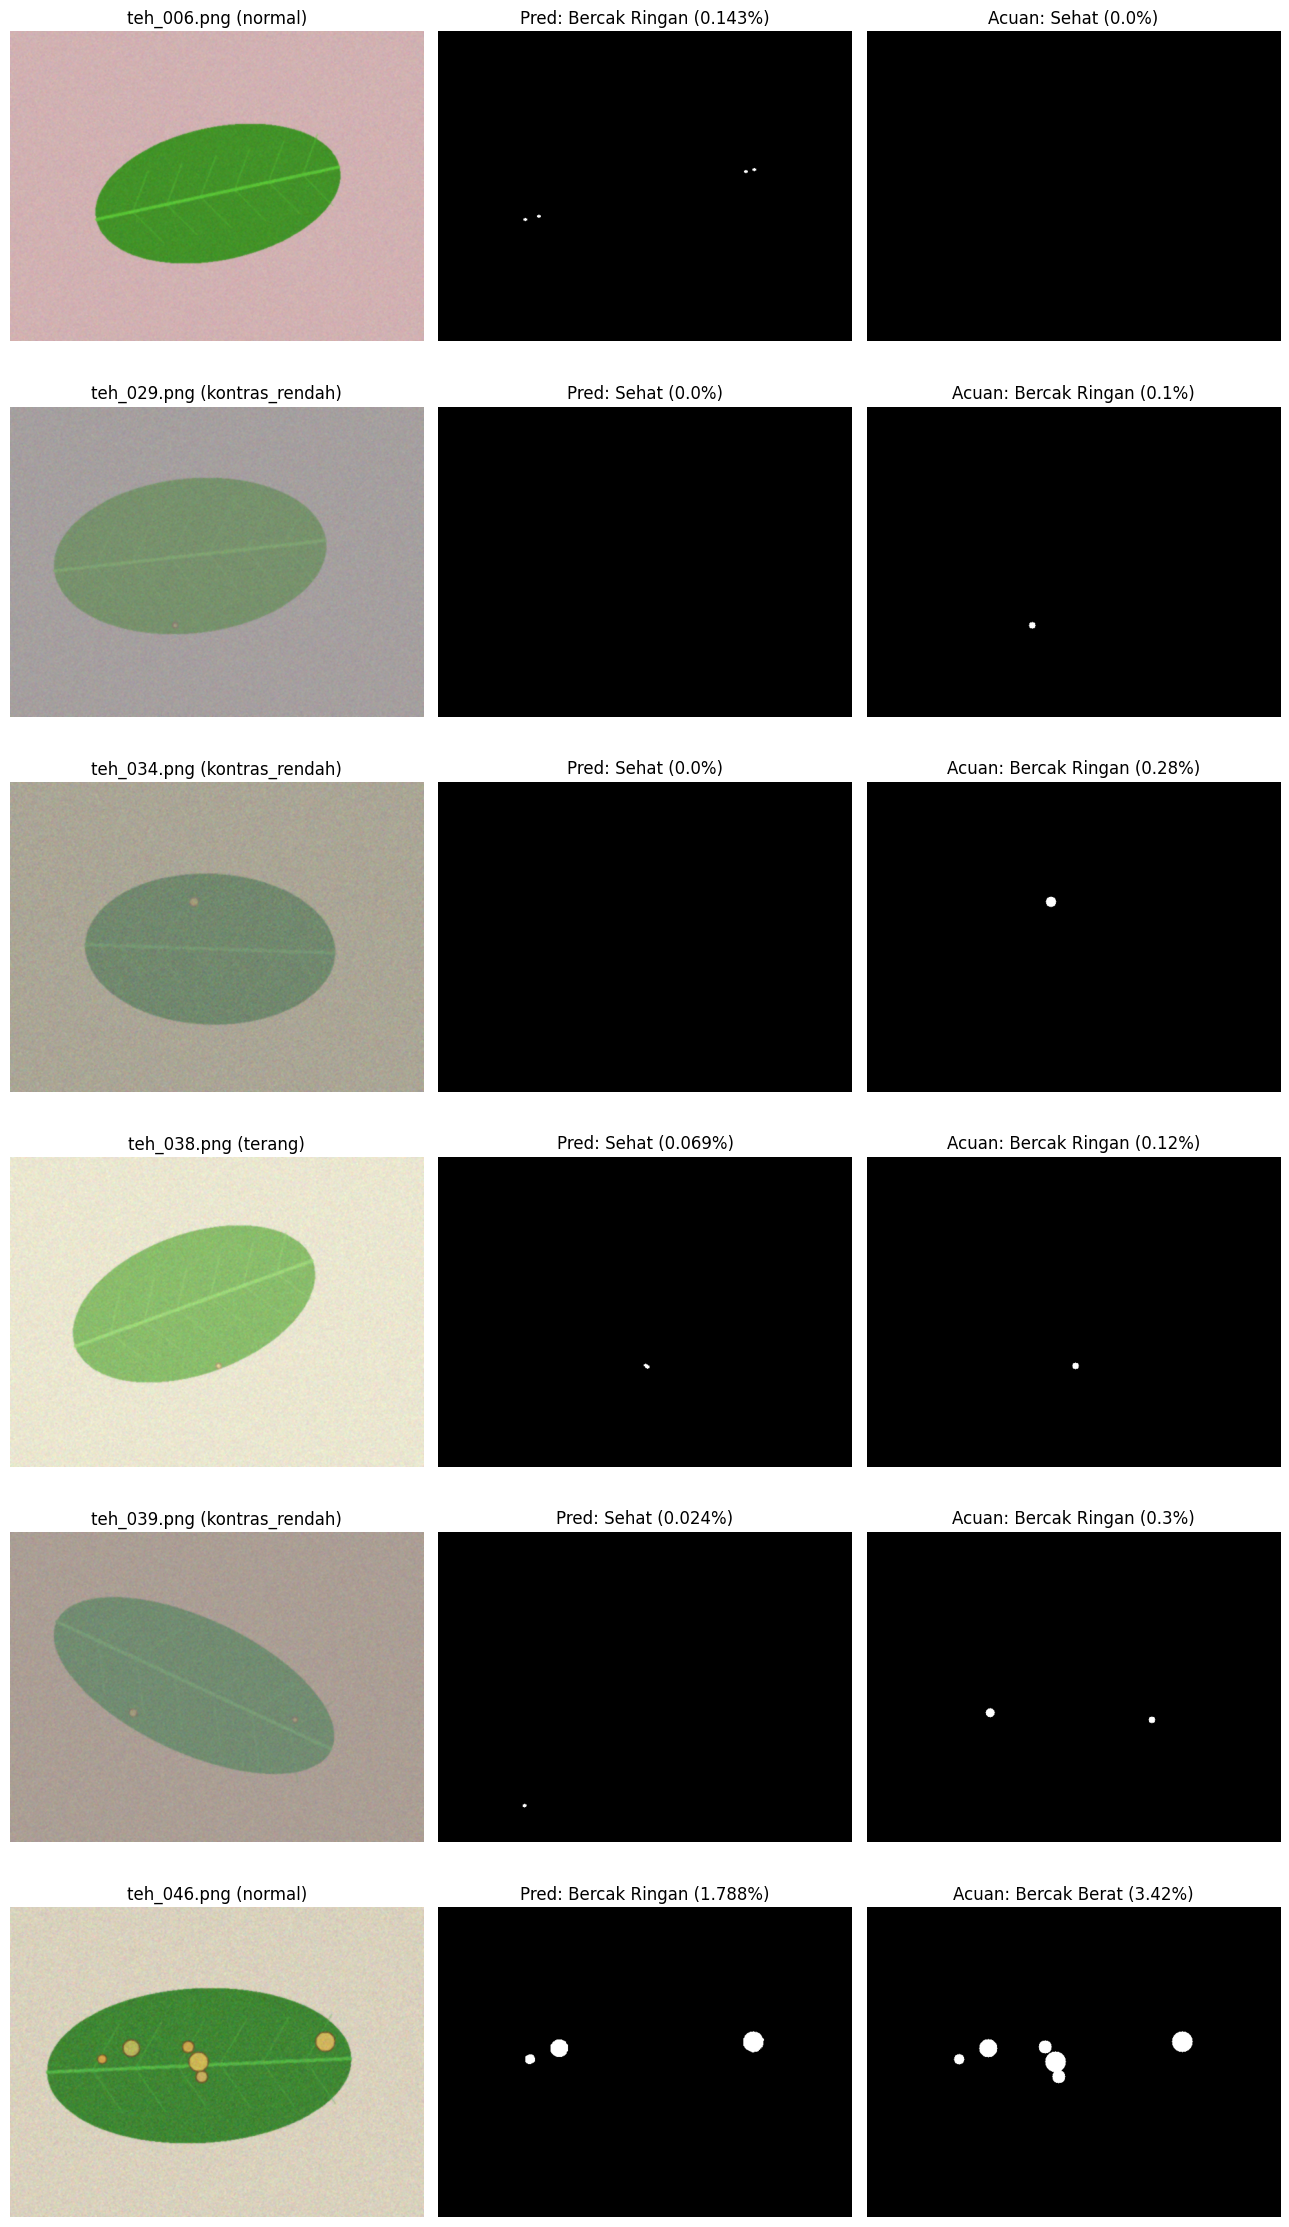

In [28]:

salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"\nJumlah citra salah kelas: {len(salah)}")
if len(salah) > 0:
    print(salah[["nama", "kondisi", "persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_acuan", "kelas_prediksi"]])
    panel_salah, judul_salah = [], []
    for _, row in salah.iterrows():
        img, md, mb = muat(row["nama"])
        pra = praproses(img, PARAM)
        h = bercak.analisis_daun(pra, PB)
        panel_salah += [pra, h["mask_bercak"], mb]
        judul_salah += [
            f"{row['nama']} ({row['kondisi']})",
            f"Pred: {row['kelas_prediksi']} ({row['persen_prediksi']}%)",
            f"Acuan: {row['kelas_acuan']} ({row['persen_acuan']}%)"
        ]
    tampil(panel_salah, judul_salah, baris=len(salah), ukuran=(13, 3.8 * len(salah)))
else:
    print("Seluruh 60 citra terklasifikasi tepat (akurasi 100%)!")


#### Langkah 5.3 — Analisis Penyebab Kesalahan pada 6 Citra yang Salah Kelas

1. **`teh_006.png` (`normal` — Acuan: `Sehat` `0,00%` $\rightarrow$ Prediksi: `Bercak Ringan` `0,143%`):**
   * **Penyebab:** Muncul **4 komponen palsu** pada bagian pangkal tulang daun/pantulan cahaya yang cukup tebal sehingga bertahan setelah *opening* SE elips $5\times5$ dan kebetulan memiliki bentuk membulat ($\text{kebulatan} \ge 0{,}5$, $\text{rasio aspek} \le 1{,}8$, $\text{luas} \ge 20\text{ px}$). Akumulasi luas keempat objek palsu tersebut mencapai `0,143%`, sedikit melampaui ambang `batas_ringan = 0,1%`[cite: 22].
2. **`teh_029.png` (`kontras_rendah` — Acuan: `Bercak Ringan` `0,10%` $\rightarrow$ Prediksi: `Sehat` `0,000%`):**
   * **Penyebab:** Pada citra `kontras_rendah`, perbedaan intensitas kanal R antara bercak tunggal berukuran kecil (`0,10%`) dan latar daun hijau sangat tipis sehingga piksel bercak gagal melewati ambang `median + 4 × MAD` (atau sisa pikselnya habis tererosi oleh SE elips $5\times5$)[cite: 7, 30].
3. **`teh_034.png` (`kontras_rendah` — Acuan: `Bercak Ringan` `0,28%` $\rightarrow$ Prediksi: `Sehat` `0,000%`):**
   * **Penyebab:** Bercak yang pudar akibat rendahnya rentang dinamis pada kondisi `kontras_rendah` tidak cukup kontras terhadap nilai median daun di kanal R pada tahap `bercak_awal`, sehingga tidak ada komponen bercak yang lolos ambang biner awal[cite: 7, 30].
4. **`teh_038.png` (`terang` — Acuan: `Bercak Ringan` `0,12%` $\rightarrow$ Prediksi: `Sehat` `0,069%`):**
   * **Penyebab:** Satu-satunya bercak pada citra ini tetap berhasil dideteksi (`jumlah_prediksi = 1`), tetapi pencahayaan berlebih (`terang`) meningkatkan nilai median daun dan mengikis tepi bercak saat ambang `median + 4 × MAD` serta *opening* $5\times5$. Luasnya menyusut dari `0,12%` menjadi `0,069%`, berada tepat di bawah ambang `batas_ringan = 0,1%`[cite: 22].
5. **`teh_039.png` (`kontras_rendah` — Acuan: `Bercak Ringan` `0,30%` $\rightarrow$ Prediksi: `Sehat` `0,024%`):**
   * **Penyebab:** Dari 2 bercak acuan pada citra kontras rendah ini, 1 bercak pudar hilang seluruhnya dan 1 bercak lainnya menyusut drastis akibat lemahnya beda intensitas di kanal R, sehingga persentase luas terukur hanya `0,024%` ($< 0{,}1\%$)[cite: 7, 22].
6. **`teh_046.png` (`normal` — Acuan: `Bercak Berat` `3,42%` $\rightarrow$ Prediksi: `Bercak Ringan` `1,788%`):**
   * **Penyebab:** Terdapat bercak penyakit yang saling berdekatan dan menyatu sehingga membentuk komponen memanjang dengan $\text{rasio aspek} > 1{,}8$ dan ikut terbuang oleh aturan penyaringan bentuk `rasio_maks`[cite: 21, 22]. Hilangnya komponen gabungan tersebut menurunkan total luas terukur menjadi `1,788%`, sedikit di bawah ambang `batas_berat = 2,0%`[cite: 22].

### Langkah 5.4 Justifikasi parameter.

#### Tabel 13. Justifikasi Parameter Final Modul `bercak.py` (`param_bercak.json`)

| Parameter | Nilai final | Alasan dan bukti (rujuk tabel atau gambar) | Risiko bila salah atur |
| :--- | :---: | :--- | :--- |
| **`kanal` dan `k`** | `kanal = 2 (R)`, `k = 4.0` | Kanal R menekan tepi palsu tulang daun menjadi `0,0` piksel pada daun sehat (**Kode 2.3**)[cite: 13], sedangkan `k = 4.0` memberi keseimbangan optimal antara IoU bercak (`0,812` berat; `0,510` ringan) dan rendahnya derau dibanding `k = 3` atau `k = 6` (**Kode 3.3 / Tabel 9**)[cite: 17]. | Bila `k` terlalu kecil ($\le 3$), titik derau dan tulang daun lolos; bila `k` terlalu besar ($\ge 6$), bercak pudar pada kelas ringan/kontras rendah hilang. |
| **`se_bentuk`, `se_open`, `se_close`** | `"elips"`, `5`, `5` | Bentuk `elips` paling sesuai dengan geometri bercak membulat; urutan *opening* lalu *closing* ukuran `5x5` membuang derau tipis sekaligus menutup lubang bercak (**Gambar 4 & Tabel 9**)[cite: 16, 17]. | Bila terlalu kecil (`3x3`), galat jumlah ringan melonjak (`78,20`)[cite: 17]; bila terlalu besar (`7x7`), bercak kecil kelas ringan ikut terhapus[cite: 17]. |
| **`luas_min`** | `20` piksel | Menghapus fragmen derau sisa morfologi dan menurunkan galat jumlah kelas ringan dari `3,70` menjadi `2,15` tanpa menaikkan galat kelas berat (`0,55`) (**Tabel 11 & Diagram Sebar Langkah 4.4**)[cite: 20, 21]. | Bila terlalu kecil, derau mikro pada daun sehat lolos; bila terlalu besar, bercak stadium awal (kelas ringan) terbuang. |
| **`bulat_min` dan `rasio_maks`** | `0.5` dan `1.8` | Memisahkan bercak kompak ($\text{kebulatan} \ge 0{,}79$, $\text{rasio} \approx 1{,}0$) dari potongan tulang daun memanjang ($\text{kebulatan} \approx 0{,}38$, $\text{rasio} = 6{,}0$), menekan galat ringan ke `0,70` dan sehat ke `0,35` (**Langkah 4.1, Tabel 11, Diagram Sebar 4.4**)[cite: 19, 20, 21]. | Bila terlalu longgar, tulang daun lolos sebagai bercak palsu; bila terlalu ketat, bercak nyata yang menyatu atau tidak beraturan ikut terbuang (seperti pada `teh_046.png`)[cite: 21]. |
| **`batas_ringan` dan `batas_berat`** | `0.1%` dan `2.0%` | Memisahkan kelas `Sehat` ($< 0{,}1\%$), `Bercak Ringan` ($0{,}1\%$–$< 2{,}0\%$), dan `Bercak Berat` ($\ge 2{,}0\%$) dengan akurasi keseluruhan **`90,0%`** (**Tabel 12**)[cite: 22, 24]. | Bila batas terlalu rendah, daun sehat dengan sisa derau kecil masuk kelas ringan; bila terlalu tinggi, daun sakit terlewat sebagai sehat. |

### Jawaban Pertanyaan Analisis Bagian 5
**P5.1 — Ketepatan SIMUTEH v0.3 dan Ringkasan Penyebab Kesalahan**
* **Ketepatan pengukuran dan klasifikasi:** Pada 60 citra dataset (`SEED = 1077`), SIMUTEH v0.3 mencapai **korelasi `0,955`** antara persentase bercak prediksi dan acuan, **galat absolut rerata `0,450%`**, serta **akurasi klasifikasi kelas `90,0%` (54/60 citra tepat)** (**Tabel 12**)[cite: 24]. Pada kondisi pencahayaan `bayangan` dan `gelap`, akurasinya mencapai **`100%`**[cite: 24].
* **Ringkasan 6 kesalahan (merujuk Langkah 5.3):** Empat kesalahan berupa *false negative* pada kelas `Bercak Ringan` (`teh_029`, `teh_034`, `teh_038`, `teh_039`) yang diprediksi `Sehat` karena rendahnya kontras lokal (`kontras_rendah`) atau pencahayaan berlebih (`terang`) membuat bercak kecil tidak lolos ambang `median + 4 × MAD` atau terkikis erosi hingga luasnya di bawah `0,1%`[cite: 22, 24]. Satu kesalahan berupa *false positive* pada daun `Sehat` (`teh_006.png`) akibat 4 segmen tulang daun/pantulan membulat yang lolos penyaringan (`0,143%`)[cite: 24]. Satu kesalahan lainnya (`teh_046.png`) menurunkan kelas `Bercak Berat` (`3,42%`) menjadi `Bercak Ringan` (`1,788%`) karena dua bercak yang menyatu membentuk komponen memanjang ($\text{rasio aspek} > 1{,}8$) dan terbuang oleh penyaringan bentuk[cite: 21, 24].

#### **P5.2 — Bias Optimistis pada Pemilihan Batas Kelas dan Strategi Evaluasi yang Benar**
* **Mengapa penentuan batas dari seluruh `label.csv` terlalu optimistis:** Ketika ambang keputusan (`0,1%` dan `2,0%`) disetel dengan mengamati distribusi seluruh 60 citra evaluasi sekaligus, parameter tersebut mengalami kebocoran data (*data leakage*) dan menyesuaikan diri secara spesifik (*overfitting*) terhadap karakteristik dataset tersebut, sehingga angka akurasi `90,0%` cenderung lebih tinggi dibandingkan performa saat menghadapi data baru yang belum pernah dilihat[cite: 25].
* **Cara penentuan batas yang benar (kaitannya dengan Pertemuan 11):** Dataset harus dipisah sejak awal menjadi **data latih (*training set*)**, **data validasi (*validation set*)**, dan **data uji (*test set*)**[cite: 25]. Nilai batas kelas dan ambang morfologi dicari hanya menggunakan **data latih/validasi** (misalnya melalui validasi silang *k-fold*), sedangkan **data uji** disimpan terpisah dan hanya dipakai satu kali di akhir untuk mengukur akurasi generalisasi yang objektif[cite: 25].

#### **P5.3 — Kondisi Cahaya Paling Bermasalah dan Usulan Perbaikan pada Pertemuan 7**
* **Kondisi cahaya paling bermasalah dan sumber kesalahannya:** Kondisi **`kontras_rendah`** menghasilkan akurasi terendah yaitu **`75%`** (3 kesalahan pada `teh_029`, `teh_034`, dan `teh_039`)[cite: 24, 25]. Kesalahan ini terutama berasal dari tahap **pembuatan citra biner awal (`bercak_awal`)** yang masih memakai ambang global berbasis `median + 4 × MAD` pada satu kanal R[cite: 7, 25, 30]. Pada citra berkontras rendah, selisih intensitas bercak pudar terhadap median daun berada di bawah $4 \times \text{MAD}$ sehingga bercak hilang sebelum masuk ke tahap morfologi[cite: 25, 30].
* **Usulan perbaikan untuk diuji pada Pertemuan 7:** Mengganti `bercak_awal` dan `mask_daun_awal` dengan metode segmentasi yang lebih adaptif pada P7, seperti **ambang adaptif lokal**, **ambang Otsu bertingkat pada ruang warna CIE $L^*a^*b^*$ (kanal $a^*$ dan $b^*$ yang memisahkan warna kuning-cokelat bercak dari hijau daun secara lebih peka daripada intensitas R)**, atau **transformasi *top-hat* morfologi** untuk menonjolkan bercak kecil sebelum pengambangan[cite: 25, 29].

#### **P5.4 — Dampak Kesalahan bagi Kelompok Tani serta Penerapan Nilai Amanah dan Transparansi**
* **Kesalahan yang lebih merugikan bagi petani:** Bagi kelompok tani teh rakyat, **daun berbercak yang dinilai sehat (*false negative*)** jauh lebih merugikan daripada daun sehat yang dinilai berbercak (*false positive*)[cite: 25]. Jika daun yang mulai terinfeksi dinyatakan sehat, petani akan menunda tindakan pengendalian sehingga penyakit menyebar cepat ke seluruh kebun dan menurunkan mutu panen secara drastis; sebaliknya, *false positive* hanya mendorong petani memeriksa ulang daun tersebut secara langsung[cite: 25].
* **Penyesuaian parameter dan konsekuensinya:** Untuk menekan *false negative*, sensitivitas deteksi dapat dinaikkan dengan **menurunkan ambang `k`** (misalnya dari `4,0` menjadi `3,5`), **memperkecil `se_open`** (dari `5` menjadi `3`), atau **menurunkan `batas_ringan`** (dari `0,1%` menjadi `0,05%`)[cite: 22, 25]. Konsekuensinya, tingkat *false positive* pada daun sehat akan meningkat karena titik derau atau tulang daun lebih mudah lolos sebagai bercak[cite: 25].
* **Penyajian hasil yang amanah dan transparan:** SIMUTEH tidak boleh hanya menampilkan label kelas akhir secara tertutup, melainkan wajib menyajikan **citra daun dengan *overlay* kontur/mask bercak yang terdeteksi**, **angka persentase luas bercak beserta luas dalam $\text{mm}^2$**, serta **peringatan pemeriksaan manual** apabila persentase berada di dekat ambang batas kelas (misalnya $0{,}05\%$–$0{,}15\%$) atau citra terdeteksi berkontras rendah, sehingga petugas lapangan dapat memverifikasi kebenaran deteksi secara langsung[cite: 25].

#### **P5.5 — Keterbatasan Asumsi Bentuk Lingkaran Sintetis dan Pengujian pada Foto Nyata**
* **Aturan yang terlalu cocok dengan data sintetis:** Aturan penyaringan geometri pada `ukur_dan_saring`—khususnya syarat **$\text{kebulatan} \ge 0{,}5$** dan **$\text{rasio aspek} \le 1{,}8$**—sangat sesuai untuk bercak sintetis yang berbentuk lingkaran sempurna, tetapi berisiko gagal pada foto lapangan nyata[cite: 22, 25]. Bercak penyakit daun teh di lapangan (seperti *blister blight* atau *brown blight*) sering berbentuk tidak beraturan, bergerigi, memanjang mengikuti tulang daun, atau saling menyatu membentuk bercak besar dengan kebulatan rendah ($< 0{,}5$) dan rasio aspek tinggi ($> 1{,}8$)[cite: 25].
* **Cara mengujinya pada data nyata:** Mengumpulkan sampel foto daun teh berpenyakit dari kebun rakyat yang telah diberi anotasi mask oleh pakar agronomi, lalu memetakan ulang diagram sebar kebulatan vs rasio aspek bercak asli terhadap artefak tulang daun[cite: 21, 25]. Berdasarkan distribusi nyata tersebut, ambang bentuk dapat dilonggarkan atau diganti dengan **fitur warna dan tekstur** (seperti indeks warna kecokelatan pada ruang $L^*a^*b^*$ atau HSV) agar bercak tak beraturan tetap terdeteksi[cite: 25].

In [31]:
# === SEL 11: LANGKAH 5.5 - UPDATE README.md, COMMIT, & TAG v0.3-morfologi ===
%cd /content/drive/MyDrive/simuteh-2330511077

baris_readme = [
    "# SIMUTEH — Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra",
    "",
    "Repositori praktikum berkelanjutan mata kuliah **Computer Vision** (Program Studi Teknik Informatika, Universitas Muhammadiyah Sukabumi).",
    "",
    "- **NIM / SEED Dataset:** `2330511077` / `SEED = 1077`",
    "- **Status Rilis:**",
    "  - `v0.1-praproses`: Rangkaian praproses citra (`src/praproses.py`, `hasil/param_praproses.json`)",
    "  - `v0.2-tepi`: Evaluasi deteksi tepi Sobel, Prewitt, LoG, dan Canny persentil (`notebook/P5_tepi.ipynb`, `src/utils_tepi.py`)",
    "  - `v0.3-morfologi`: Operasi morfologi biner, analisis komponen terhubung, dan modul analisis bercak (`notebook/P6_morfologi.ipynb`, `src/bercak.py`, `hasil/param_bercak.json`)",
    "",
    "## Ringkasan Hasil Pertemuan 5–6",
    "1. **Deteksi Tepi (`v0.2-tepi`):** Kanal `R` menghasilkan `0,0` piksel tepi palsu tulang daun pada seluruh kondisi cahaya daun sehat (dibandingkan `846,5` piksel pada kanal `Gray` kondisi bayangan). Gradien morfologi dari mask daun menghasilkan batas daun yang lebih utuh pada citra kontras rendah.",
    "2. **Morfologi & Analisis Bercak (`v0.3-morfologi`):**",
    "   - Kombinasi terbaik: ambang `median + 4.0 * MAD` pada kanal `R`, diikuti *opening* dan *closing* dengan SE `elips 5x5`, serta penyaringan komponen terhubung (`luas >= 20 px`, `kebulatan >= 0.5`, `rasio_aspek <= 1.8`).",
    "   - Evaluasi pada 60 citra menghasilkan **akurasi kelas `90,0%`**, **korelasi luas `0,955`**, dan **galat absolut rerata `0,450%`**.",
    "",
    "## Cara Menggunakan Modul `src/bercak.py`",
    "~~~python",
    "import json, cv2",
    "from src.praproses import praproses",
    "from src.bercak import analisis_daun",
    "",
    'param_pra = json.load(open("hasil/param_praproses.json"))',
    'param_bercak = json.load(open("hasil/param_bercak.json"))',
    "",
    'img = cv2.imread("data/sintetis/citra/teh_041.png")',
    "img_bersih = praproses(img, param_pra)",
    "hasil = analisis_daun(img_bersih, param_bercak)",
    "",
    'print(hasil["kelas"], hasil["persen_bercak"], hasil["jumlah_bercak"])',
    "~~~",
]

with open("README.md", "w", encoding="utf-8") as f:
    f.write("\n".join(baris_readme) + "\n")

!pip freeze | grep -E "opencv|numpy|pandas|matplotlib" > requirements.txt

!git add README.md requirements.txt notebook/P6_morfologi.ipynb src/bercak.py hasil/param_bercak.json hasil/p6_eksperimen_se.csv hasil/p6_evaluasi_bercak.csv
!git commit -m "Selesai Pertemuan 6: morfologi biner, komponen terhubung, dan modul bercak.py"
!git tag v0.3-morfologi
!git push origin main
!git push --tags

/content/drive/MyDrive/simuteh-2330511077
fatal: pathspec 'notebook/P6_morfologi.ipynb' did not match any files
^C
remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/MasHudaaa/simuteh-1077.git/'
remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/MasHudaaa/simuteh-1077.git/'
